<a href="https://colab.research.google.com/github/adammahabayu/railway-defect-detection-yolov8/blob/main/railway_defect_detection_yolov8_baseline_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Railway Defect Detection using YOLOv8

Notebook eksperimen untuk deteksi cacat rel kereta api menggunakan YOLOv8.

**Tujuan notebook**
- Memeriksa konfigurasi dan struktur dataset.
- Memuat bobot model yang sudah dilatih.
- Menampilkan contoh prediksi.
- Mengevaluasi model terpilih pada test set.
- Menyimpan artefak evaluasi ke Google Drive.

> **Catatan:** Model baseline dan eksperimen YOLOv8s sebelumnya sudah dilatih. Sel training disediakan sebagai opsional dan tidak perlu dijalankan untuk mereproduksi inferensi/evaluasi menggunakan bobot yang sudah tersimpan.

## 1. Environment setup

Jalankan sel ini jika runtime Colab baru saja di-reset. Instalasi paket tidak melatih model.

In [ ]:
%pip install -q ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 3.1 MB/s eta 0:00:00


## 2. Mount Google Drive

Pastikan model `best.pt` sudah tersimpan di Google Drive pada lokasi yang diharapkan.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 3. Konfigurasi path

Dataset harus sudah diekstrak ke `/content/railway_dataset` dan memiliki folder `train`, `valid`, serta `test`.

In [ ]:
from google.colab import drive
from pathlib import Path
import zipfile

# 1. Hubungkan Google Drive
drive.mount('/content/drive')

# 2. Tentukan lokasi dataset ZIP
zip_path = Path(
    '/content/drive/MyDrive/railway-defect-detection/rail_defects_dataset.zip'
)
dataset_root = Path('/content/railway_dataset')

# 3. Ekstrak dataset jika belum tersedia
if not (dataset_root / 'data.yaml').exists():
    if not zip_path.exists():
        raise FileNotFoundError(
            f'Dataset ZIP tidak ditemukan: {zip_path}'
        )

    dataset_root.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(dataset_root)

# 4. Cari data.yaml, termasuk jika ZIP punya folder bertingkat
yaml_files = list(dataset_root.rglob('data.yaml'))

if not yaml_files:
    raise FileNotFoundError(
        'data.yaml tidak ditemukan setelah ekstraksi. '
        'Periksa isi ZIP dataset.'
    )

yaml_path = yaml_files[0]
print('Dataset config ditemukan:', yaml_path)
print('Dataset root aktual:', yaml_path.parent)

# 5. Periksa struktur dataset
for split in ['train', 'valid', 'test']:
    image_dir = yaml_path.parent / split / 'images'
    print(f'{split} images:', image_dir.exists(), image_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset config ditemukan: /content/railway_dataset/data.yaml
Dataset root aktual: /content/railway_dataset
train images: False /content/railway_dataset/train/images
valid images: False /content/railway_dataset/valid/images
test images: False /content/railway_dataset/test/images


In [ ]:
from pathlib import Path
import yaml

ROOT = Path("/content/railway_dataset")
DATA_YAML = ROOT / "data.yaml"

MODEL_N = Path(
    "/content/drive/MyDrive/railway-defect-detection/"
    "railway_defect_yolov8n_baseline/weights/best.pt"
)
MODEL_S = Path(
    "/content/drive/MyDrive/railway-defect-detection/"
    "railway_defect_yolov8s_experiment/weights/best.pt"
)

print("Dataset root:", ROOT, "| exists:", ROOT.exists())
print("data.yaml:", DATA_YAML, "| exists:", DATA_YAML.exists())
print("YOLOv8n best.pt:", MODEL_N, "| exists:", MODEL_N.exists())
print("YOLOv8s best.pt:", MODEL_S, "| exists:", MODEL_S.exists())

Dataset root: /content/railway_dataset | exists: True
data.yaml: /content/railway_dataset/data.yaml | exists: True
YOLOv8n best.pt: /content/drive/MyDrive/railway-defect-detection/railway_defect_yolov8n_baseline/weights/best.pt | exists: True
YOLOv8s best.pt: /content/drive/MyDrive/railway-defect-detection/railway_defect_yolov8s_experiment/weights/best.pt | exists: True


In [ ]:
from pathlib import Path

root = Path('/content/railway_dataset')

print("Isi folder dataset:")
for p in list(root.iterdir())[:30]:
    print(p)

print("\nLokasi folder images yang ditemukan:")
for p in root.rglob('images'):
    print(p)

print("\nIsi data.yaml:")
print((root / 'data.yaml').read_text())

Isi folder dataset:
/content/railway_dataset/train\labels\20231018_112728_mp4-0213_jpg.rf.5b985b3bcba21c37760ce3a427c26719.txt
/content/railway_dataset/test\labels\20231018_112728_mp4-0320_jpg.rf.36f2eaf6ec816bd3a37d92b31a1a8500.txt
/content/railway_dataset/valid\labels\VID-20231018-WA0019_mp4-0120_jpg.rf.ae8347d598c4aff6407c34a8abb2ec36.txt
/content/railway_dataset/train\images\IMG_20201211_113506_jpg.rf.4cdae60504a271cb98d8e6aee4142963.jpg
/content/railway_dataset/valid\labels\20231018_113043_mp4-0121_jpg.rf.420d0007315cf673a6ba1f9075a99300.txt
/content/railway_dataset/train\images\VID-20231018-WA0012_mp4-0186_jpg.rf.ae3729524c7fdd1151442cb805730af9.jpg
/content/railway_dataset/train\labels\VID-20231018-WA0017_mp4-0204_jpg.rf.d84d3f76c959a9a213e84288e5557b2c.txt
/content/railway_dataset/train\images\VID-20231018-WA0011_mp4-0095_jpg.rf.c495617d99e07d78f16e461fb2789a1c.jpg
/content/railway_dataset/valid\images\WhatsApp-Video-2023-11-01-at-21_27_09_74abd296_mp4-0128_jpg.rf.b10b0f763b6b0

In [ ]:
from pathlib import Path
import shutil

ROOT = Path("/content/railway_dataset")

# Buat struktur folder yang dibutuhkan YOLOv8
for split in ["train", "valid", "test"]:
    for kind in ["images", "labels"]:
        (ROOT / split / kind).mkdir(parents=True, exist_ok=True)

# Pindahkan file yang nama path-nya memakai backslash
moved = 0
for p in list(ROOT.iterdir()):
    if not p.is_file() or "\\" not in p.name:
        continue

    parts = p.name.split("\\")
    if len(parts) < 3:
        continue

    split, kind = parts[0], parts[1]
    if split not in {"train", "valid", "test"}:
        continue
    if kind not in {"images", "labels"}:
        continue

    destination = ROOT / split / kind / "\\".join(parts[2:])
    if destination.exists():
        print("Lewati, file tujuan sudah ada:", destination.name)
        continue

    shutil.move(str(p), str(destination))
    moved += 1

print("Jumlah file dipindahkan:", moved)

# Periksa struktur folder hasil perbaikan
for split in ["train", "valid", "test"]:
    for kind in ["images", "labels"]:
        folder = ROOT / split / kind
        print(f"{split}/{kind}: {len(list(folder.iterdir()))} file")

Jumlah file dipindahkan: 15284
train/images: 6781 file
train/labels: 6681 file
valid/images: 606 file
valid/labels: 606 file
test/images: 310 file
test/labels: 300 file


## 4. Periksa struktur dataset

Jumlah yang tercatat dari pemeriksaan dataset sebelumnya:
- Train: 6.781 gambar, 6.681 file label
- Validation: 606 gambar, 606 file label
- Test: 310 gambar, 300 file label

Sel berikut menghitung ulang jumlah file yang tersedia di runtime saat ini.

In [ ]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(folder):
    folder = Path(folder)
    return sum(1 for p in folder.iterdir()
               if p.is_file() and p.suffix.lower() in IMAGE_EXTS) if folder.exists() else 0

def count_labels(folder):
    folder = Path(folder)
    return sum(1 for p in folder.glob("*.txt") if p.is_file()) if folder.exists() else 0

for split in ("train", "valid", "test"):
    images = count_images(ROOT / split / "images")
    labels = count_labels(ROOT / split / "labels")
    print(f"{split:>5}: {images:>5} gambar | {labels:>5} file label")

train:  6681 gambar |  6681 file label
valid:   606 gambar |   606 file label
 test:   300 gambar |   300 file label


In [ ]:
from pathlib import Path

ROOT = Path("/content/railway_dataset")

for split in ["train", "valid", "test"]:
    img_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    images = list(img_dir.glob("*"))
    missing_labels = [
        img.name for img in images
        if not (label_dir / f"{img.stem}.txt").exists()
    ]

    print(f"\n{split}: {len(missing_labels)} gambar tanpa file label")
    for name in missing_labels[:10]:
        print(" -", name)


train: 0 gambar tanpa file label

valid: 0 gambar tanpa file label

test: 0 gambar tanpa file label


In [ ]:
from pathlib import Path

ROOT = Path("/content/railway_dataset")

for split in ["train", "test"]:
    img_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    found_without_suffix = []
    not_found = []

    for img in img_dir.iterdir():
        if not img.is_file():
            continue

        if (label_dir / f"{img.stem}.txt").exists():
            continue

        # Contoh: nama_gambar(1).jpg -> nama_gambar.txt
        stem_without_suffix = img.stem
        if stem_without_suffix.endswith("(1)"):
            stem_without_suffix = stem_without_suffix[:-3]

        candidate = label_dir / f"{stem_without_suffix}.txt"

        if candidate.exists():
            found_without_suffix.append((img.name, candidate.name))
        else:
            not_found.append(img.name)

    print(f"\n{split.upper()}")
    print("Label ditemukan setelah menghapus akhiran (1):",
          len(found_without_suffix))
    print("Tetap tidak ditemukan:", len(not_found))

    for image_name, label_name in found_without_suffix[:5]:
        print(f"  {image_name} -> {label_name}")


TRAIN
Label ditemukan setelah menghapus akhiran (1): 100
Tetap tidak ditemukan: 0
  IMG_20201114_101143_jpg.rf.a6b2e31b9a4ced97815a7668e1629316(1).jpg -> IMG_20201114_101143_jpg.rf.a6b2e31b9a4ced97815a7668e1629316.txt
  VID-20231018-WA0018_mp4-0069_jpg.rf.cc1cac49948a92b40d25c53a7fe691a4(1).jpg -> VID-20231018-WA0018_mp4-0069_jpg.rf.cc1cac49948a92b40d25c53a7fe691a4.txt
  IMG_20201211_112807_jpg.rf.a7ddc8d3d7c872dac6687824ad54562a(1).jpg -> IMG_20201211_112807_jpg.rf.a7ddc8d3d7c872dac6687824ad54562a.txt
  VID-20231018-WA0004_mp4-0119_jpg.rf.f9bd17fafd902faafebc12fe4732d981(1).jpg -> VID-20231018-WA0004_mp4-0119_jpg.rf.f9bd17fafd902faafebc12fe4732d981.txt
  20231018_120709_mp4-0050_jpg.rf.decb9a8a2ddd16e176f278dadae2dc34(1).jpg -> 20231018_120709_mp4-0050_jpg.rf.decb9a8a2ddd16e176f278dadae2dc34.txt

TEST
Label ditemukan setelah menghapus akhiran (1): 10
Tetap tidak ditemukan: 0
  VID-20231018-WA0005_mp4-0188_jpg.rf.5d0ac4a1663856d6d8cc645ca4f78cbd(1).jpg -> VID-20231018-WA0005_mp4-0188_

In [ ]:
from pathlib import Path

ROOT = Path("/content/railway_dataset")
renamed = 0
skipped = []

for split in ["train", "test"]:
    img_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    for img in list(img_dir.iterdir()):
        if not img.is_file() or not img.stem.endswith("(1)"):
            continue

        new_stem = img.stem[:-3]
        new_img = img.with_name(new_stem + img.suffix)
        label = label_dir / f"{new_stem}.txt"

        if not label.exists():
            skipped.append((img.name, "label tidak ditemukan"))
            continue

        if new_img.exists():
            skipped.append((img.name, "nama tujuan sudah ada"))
            continue

        img.rename(new_img)
        renamed += 1

print("Gambar berhasil diganti nama:", renamed)
print("Gambar dilewati:", len(skipped))
for item in skipped[:10]:
    print(item)

Gambar berhasil diganti nama: 0
Gambar dilewati: 110
('IMG_20201114_101143_jpg.rf.a6b2e31b9a4ced97815a7668e1629316(1).jpg', 'nama tujuan sudah ada')
('VID-20231018-WA0018_mp4-0069_jpg.rf.cc1cac49948a92b40d25c53a7fe691a4(1).jpg', 'nama tujuan sudah ada')
('IMG_20201211_112807_jpg.rf.a7ddc8d3d7c872dac6687824ad54562a(1).jpg', 'nama tujuan sudah ada')
('VID-20231018-WA0004_mp4-0119_jpg.rf.f9bd17fafd902faafebc12fe4732d981(1).jpg', 'nama tujuan sudah ada')
('20231018_120709_mp4-0050_jpg.rf.decb9a8a2ddd16e176f278dadae2dc34(1).jpg', 'nama tujuan sudah ada')
('VID-20231018-WA0016_mp4-0163_jpg.rf.c64d3de6ca071ce41933eca745833232(1).jpg', 'nama tujuan sudah ada')
('20231018_120709_mp4-0049_jpg.rf.7833efb5ea2759c84499e641da474e3a(1).jpg', 'nama tujuan sudah ada')
('20231018_114952_mp4-0244_jpg.rf.6f934448e54cb52aebb3dd4cfb904a3b(1).jpg', 'nama tujuan sudah ada')
('20231018_114952_mp4-0244_jpg.rf.26986db60c879e3a32291ad01ec8e968(1).jpg', 'nama tujuan sudah ada')
('20231018_120709_mp4-0048_jpg.rf.5b

In [ ]:
from pathlib import Path
import hashlib

ROOT = Path("/content/railway_dataset")

for split in ["train", "test"]:
    img_dir = ROOT / split / "images"
    label_dir = ROOT / split / "labels"

    print(f"\n--- {split.upper()} ---")
    checked = 0

    for img in img_dir.iterdir():
        if not img.is_file() or not img.stem.endswith("(1)"):
            continue

        original_name = img.stem[:-3] + img.suffix
        original_img = img_dir / original_name
        label_name = img.stem[:-3] + ".txt"
        label = label_dir / label_name

        print(f"\nGambar: {img.name}")
        print("Gambar tanpa (1) ada:", original_img.exists())
        print("Label pasangan ada:", label.exists())

        if original_img.exists():
            def md5(path):
                h = hashlib.md5()
                with path.open("rb") as f:
                    for chunk in iter(lambda: f.read(1024 * 1024), b""):
                        h.update(chunk)
                return h.hexdigest()

            print("Isi gambar identik:", md5(img) == md5(original_img))

        checked += 1
        if checked >= 3:
            break


--- TRAIN ---

Gambar: IMG_20201114_101143_jpg.rf.a6b2e31b9a4ced97815a7668e1629316(1).jpg
Gambar tanpa (1) ada: True
Label pasangan ada: True
Isi gambar identik: True

Gambar: VID-20231018-WA0018_mp4-0069_jpg.rf.cc1cac49948a92b40d25c53a7fe691a4(1).jpg
Gambar tanpa (1) ada: True
Label pasangan ada: True
Isi gambar identik: True

Gambar: IMG_20201211_112807_jpg.rf.a7ddc8d3d7c872dac6687824ad54562a(1).jpg
Gambar tanpa (1) ada: True
Label pasangan ada: True
Isi gambar identik: True

--- TEST ---

Gambar: VID-20231018-WA0005_mp4-0188_jpg.rf.5d0ac4a1663856d6d8cc645ca4f78cbd(1).jpg
Gambar tanpa (1) ada: True
Label pasangan ada: True
Isi gambar identik: True

Gambar: VID-20231018-WA0005_mp4-0086_jpg.rf.1f8b1ed357e499613178e83d9a38274a(1).jpg
Gambar tanpa (1) ada: True
Label pasangan ada: True
Isi gambar identik: True

Gambar: VID-20231018-WA0005_mp4-0177_jpg.rf.036269f01dbac968ac812c3637a12635(1).jpg
Gambar tanpa (1) ada: True
Label pasangan ada: True
Isi gambar identik: True


In [ ]:
from pathlib import Path
import hashlib

ROOT = Path("/content/railway_dataset")

def md5(path):
    h = hashlib.md5()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

removed = 0
kept = 0

for split in ["train", "test"]:
    img_dir = ROOT / split / "images"

    for img in list(img_dir.iterdir()):
        if not img.is_file() or not img.stem.endswith("(1)"):
            continue

        original = img.with_name(img.stem[:-3] + img.suffix)

        if original.exists() and md5(img) == md5(original):
            img.unlink()
            removed += 1
        else:
            kept += 1
            print("Dipertahankan untuk pemeriksaan:", img.name)

print("Duplikat identik dihapus:", removed)
print("Gambar dipertahankan:", kept)

Duplikat identik dihapus: 110
Gambar dipertahankan: 0


## 5. Periksa konfigurasi `data.yaml`

Konfigurasi menggunakan 10 ID kelas (`defect_0`–`defect_9`). Path diubah menjadi absolut agar Ultralytics tidak salah mencari folder saat notebook dijalankan.

In [ ]:
assert DATA_YAML.exists(), f"File tidak ditemukan: {DATA_YAML}"

config = yaml.safe_load(DATA_YAML.read_text(encoding="utf-8"))
config["path"] = str(ROOT)
DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")

print(DATA_YAML.read_text(encoding="utf-8"))

path: /content/railway_dataset
train: train/images
val: valid/images
test: test/images
names:
  0: defect_0
  1: defect_1
  2: defect_2
  3: defect_3
  4: defect_4
  5: defect_5
  6: defect_6
  7: defect_7
  8: defect_8
  9: defect_9



## 6. Muat model yang sudah dilatih

Bagian ini hanya memuat bobot model, bukan training.

In [ ]:
from ultralytics import YOLO

assert MODEL_N.exists(), (
    "Bobot YOLOv8n tidak ditemukan. Periksa apakah Google Drive sudah di-mount "
    "dan file best.pt berada di lokasi yang benar."
)

model_n = YOLO(str(MODEL_N))
print("Model YOLOv8n berhasil dimuat.")
print("Kelas:", model_n.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model YOLOv8n berhasil dimuat.
Kelas: {0: 'defect_0', 1: 'defect_1', 2: 'defect_2', 3: 'defect_3', 4: 'defect_4', 5: 'defect_5', 6: 'defect_6', 7: 'defect_7', 8: 'defect_8', 9: 'defect_9'}


## 7. Visualisasi prediksi pada validation set

Contoh visualisasi menggunakan enam gambar dari validation set. Ini adalah pemeriksaan kualitatif, bukan evaluasi final.

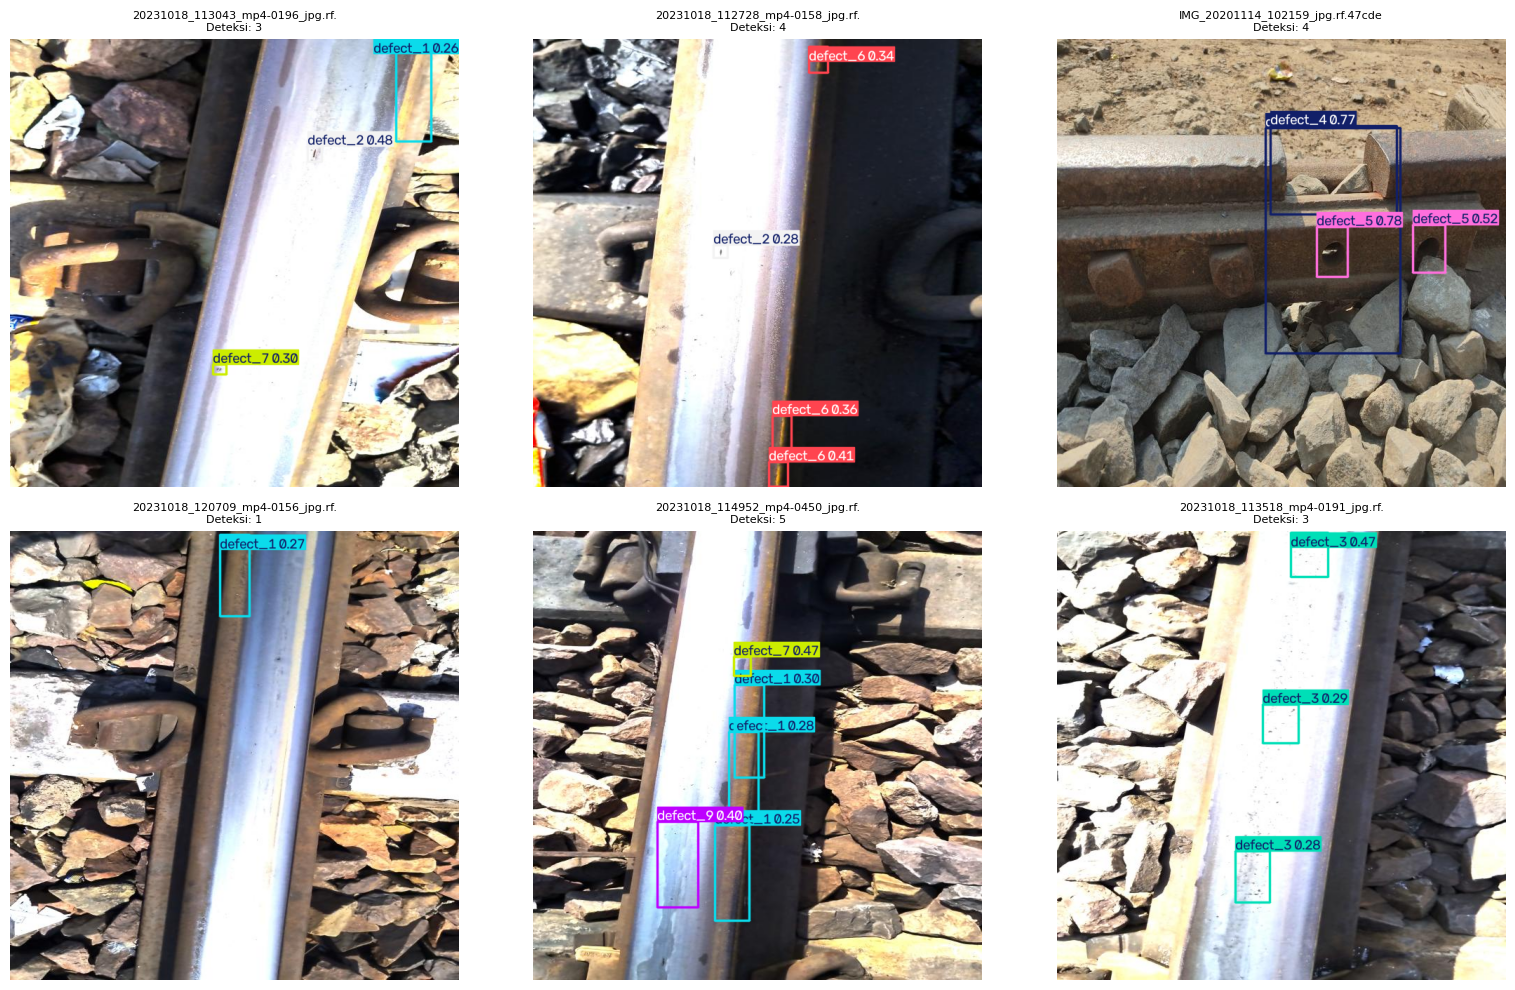

In [ ]:
import random
import matplotlib.pyplot as plt

image_dir = ROOT / "valid" / "images"
image_paths = sorted(
    p for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)

assert image_paths, f"Tidak ada gambar yang ditemukan di {image_dir}"

random.seed(42)
samples = random.sample(image_paths, min(6, len(image_paths)))

predictions = model_n.predict(
    source=[str(p) for p in samples],
    imgsz=640,
    conf=0.25,
    verbose=False
)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, result in zip(axes, predictions):
    ax.imshow(result.plot()[..., ::-1])
    ax.set_title(f"{Path(result.path).name[:32]}\nDeteksi: {len(result.boxes)}", fontsize=8)
    ax.axis("off")

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Evaluasi final pada test set

Jalankan evaluasi test set setelah model yang akan dilaporkan ditentukan. Jangan gunakan test set berulang kali untuk memilih hyperparameter.

Hasil YOLOv8n yang tercatat pada evaluasi sebelumnya:
- Precision: **0.4880**
- Recall: **0.5111**
- mAP50: **0.4671**
- mAP50–95: **0.1846**

Angka tersebut adalah hasil terdahulu; sel di bawah menjalankan evaluasi ulang. Nilai hasil runtime saat ini yang dicetak oleh sel kode menjadi acuan jika berbeda.


In [ ]:
metrics_test = model_n.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    workers=2,
    plots=True,
    verbose=True
)

print("\n===== YOLOv8n — TEST SET =====")
print(f"Precision : {metrics_test.box.mp:.4f}")
print(f"Recall    : {metrics_test.box.mr:.4f}")
print(f"mAP50     : {metrics_test.box.map50:.4f}")
print(f"mAP50-95  : {metrics_test.box.map:.4f}")

Ultralytics 8.4.176 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1094.1±408.3 MB/s, size: 61.2 KB)
val: Scanning /content/railway_dataset/test/labels... 300 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 1.9Kit/s 0.2s
val: New cache created: /content/railway_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 38/38 2.2s/it 1:22
                   all        300       1494      0.489      0.513      0.471      0.186
              defect_1         92        298      0.416      0.481      0.404       0.15
              defect_2         84        234      0.404      0.256      0.255     0.0814
              defect_3         70        157      0.436      0.325       0.32     0.0995
              defect_4          8         11      0.495          1   

## 9. Simpan artefak evaluasi ke Google Drive

Sel evaluasi Ultralytics mengembalikan lokasi hasil melalui `metrics_test.save_dir`. Sel berikut menggunakan lokasi tersebut, sehingga tidak bergantung pada asumsi folder `/content/runs/detect/val`.


In [ ]:
import shutil
import csv

RESULTS_DIR = Path(metrics_test.save_dir)
DRIVE_RESULTS = Path(
    "/content/drive/MyDrive/railway-defect-detection/"
    "final_test_yolov8n_recheck"
)
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

if RESULTS_DIR.exists():
    for item in RESULTS_DIR.iterdir():
        target = DRIVE_RESULTS / item.name
        if item.is_dir():
            shutil.copytree(item, target, dirs_exist_ok=True)
        else:
            shutil.copy2(item, target)
    print("Artefak evaluasi disalin ke:", DRIVE_RESULTS)
else:
    print("Folder hasil evaluasi tidak ditemukan:", RESULTS_DIR)

metrics_csv = DRIVE_RESULTS / "baseline_metrics.csv"
summary_rows = [
    ("Model", "YOLOv8n"),
    ("Dataset split", "test"),
    ("Test images", count_images(ROOT / "test" / "images")),
    ("Labeled instances", sum(
        len([line for line in label_file.read_text(encoding="utf-8").splitlines() if line.strip()])
        for label_file in (ROOT / "test" / "labels").glob("*.txt")
    )),
    ("Precision", round(float(metrics_test.box.mp), 4)),
    ("Recall", round(float(metrics_test.box.mr), 4)),
    ("mAP50", round(float(metrics_test.box.map50), 4)),
    ("mAP50-95", round(float(metrics_test.box.map), 4)),
]
with metrics_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerows(summary_rows)
print("Ringkasan metrik disimpan ke:", metrics_csv)


Artefak evaluasi disalin ke: /content/drive/MyDrive/railway-defect-detection/final_test_yolov8n_recheck
Ringkasan metrik disimpan ke: /content/drive/MyDrive/railway-defect-detection/final_test_yolov8n_recheck/baseline_metrics.csv


## 10. Ringkasan Hasil Eksperimen

Bagian ini merangkum hasil eksperimen model YOLOv8n dan YOLOv8s pada dataset deteksi cacat rel. Hasil pada validation set dan test set dicatat secara terpisah karena keduanya merupakan split dataset yang berbeda.

### YOLOv8n — Validation Set

- Precision: 0.4587
- Recall: 0.4185
- mAP50: 0.3906
- mAP50–95: 0.1579

### YOLOv8s — Validation Set

- Precision: 0.4523
- Recall: 0.4520
- mAP50: 0.3837
- mAP50–95: 0.1556

### YOLOv8n — Test Set (Evaluasi Terbaru)

- Precision: 0.4886
- Recall: 0.5127
- mAP50: 0.4707
- mAP50–95: 0.1858
- Jumlah gambar test: 300
- Jumlah objek berlabel: 1.494

Evaluasi terbaru YOLOv8n dijalankan menggunakan bobot model yang telah dilatih dan konfigurasi `data.yaml` yang mengarah ke `/content/railway_dataset`. Sebelum evaluasi, 110 gambar duplikat identik yang memiliki akhiran `(1)` telah dihapus dari folder train dan test.

### Interpretasi Hasil

Pada validation set, YOLOv8n memiliki nilai mAP50 dan mAP50–95 sedikit lebih tinggi daripada YOLOv8s pada hasil eksperimen yang tercatat. YOLOv8s memiliki recall validation lebih tinggi, sedangkan precision kedua model relatif berdekatan.

Pada test set, evaluasi terbaru YOLOv8n menghasilkan precision 0.4886, recall 0.5127, mAP50 0.4707, dan mAP50–95 0.1858. Nilai tersebut menggambarkan hasil YOLOv8n pada test set yang telah dibersihkan dari duplikat identik.

### Catatan Metodologis

1. Hasil validation dan test tidak boleh dibandingkan langsung seolah-olah berasal dari split yang sama.
2. Hasil validation yang dicantumkan berasal dari eksperimen sebelumnya. Evaluasi ulang validation setelah pembersihan dataset belum tercatat.
3. Hasil test YOLOv8s belum tersedia, sehingga belum dapat dibuat perbandingan test set yang setara antara YOLOv8n dan YOLOv8s.
4. Hasil evaluasi bergantung pada bobot model, konfigurasi dataset, dan kondisi dataset saat evaluasi dilakukan.
5. Nilai metrik merupakan hasil pengukuran pada dataset ini dan tidak menjamin kinerja yang sama pada kondisi rel di dunia nyata.

## 11. Keterbatasan dan Pekerjaan Lanjutan

- **Nama kelas masih generik.** Dataset menggunakan 10 kelas (`defect_0`–`defect_9`). Nama jenis cacat yang sebenarnya perlu diverifikasi dari dokumentasi dataset sebelum diganti.
- **Jumlah objek antar kelas tidak seimbang.** Pada evaluasi test YOLOv8n terbaru, beberapa kelas memiliki jumlah objek yang sedikit, misalnya `defect_4` dengan 11 objek dan `defect_5` dengan 8 objek. Karena itu, metrik per kelas perlu ditafsirkan dengan hati-hati.
- **Performa model masih terbatas.** Evaluasi terbaru YOLOv8n pada test set menghasilkan Precision 0.4886, Recall 0.5127, mAP50 0.4707, dan mAP50–95 0.1858. Hasil ini merupakan baseline eksperimen dan belum membuktikan bahwa model layak digunakan untuk keputusan keselamatan operasional.
- **Perbandingan model belum lengkap.** Hasil validation YOLOv8n dan YOLOv8s tersedia dari eksperimen sebelumnya. Namun, evaluasi ulang pada validation set setelah pembersihan dataset belum tercatat, dan hasil YOLOv8s pada test set yang sama belum tersedia.
- **Dataset telah dibersihkan dari duplikat identik.** Sebanyak 110 gambar duplikat identik dengan akhiran `(1)` dihapus dari folder train dan test. Evaluasi YOLOv8n terbaru dilakukan setelah pembersihan tersebut. Untuk konsistensi eksperimen, hasil validation sebaiknya diperbarui menggunakan dataset yang sama.
- **Pekerjaan lanjutan:** verifikasi pemetaan kelas, evaluasi ulang kedua model pada split yang sama, analisis kesalahan deteksi per kelas, dan pengujian tambahan pada data yang mewakili kondisi rel di dunia nyata.
- **Dokumentasi portofolio:** sertakan grafik evaluasi, contoh prediksi, metrik per kelas, sumber dataset, serta keterbatasan model secara transparan.

## 12. Checklist Sebelum Publikasi

- [ ] Jalankan notebook dari awal sampai akhir pada runtime baru untuk memastikan urutan eksekusi dan dependensi benar.
- [ ] Pastikan Google Drive sudah di-mount dan path dataset, `data.yaml`, serta bobot `best.pt` sesuai.
- [ ] Pastikan struktur dataset dan jumlah gambar serta label sudah diperiksa setelah pembersihan duplikat.
- [ ] Simpan hasil evaluasi terbaru, grafik, confusion matrix, dan contoh prediksi ke Google Drive.
- [ ] Catat konfigurasi eksperimen, versi Ultralytics, parameter evaluasi, dan bobot model yang digunakan.
- [ ] Jika membandingkan YOLOv8n dengan YOLOv8s, evaluasi keduanya pada split yang sama dengan konfigurasi yang konsisten.
- [ ] Jangan menyatakan YOLOv8n lebih unggul secara keseluruhan sebelum tersedia perbandingan yang setara.
- [ ] Periksa lisensi dataset dan bobot model sebelum membagikannya.
- [ ] Jangan mengunggah dataset atau bobot berukuran besar ke GitHub tanpa memeriksa lisensi, batas penyimpanan, dan kebutuhan proyek.
- [ ] Cantumkan sumber dataset, informasi lisensi, cara menjalankan notebook, metrik evaluasi, dan keterbatasan model di README.
- [ ] Nyatakan dengan jelas bahwa hasil ini merupakan eksperimen baseline, bukan sertifikasi atau validasi keselamatan untuk penggunaan operasional.